# Repeated runs over 10 seeds — Responsible AI on UCI Adult
This notebook reruns the pipeline (split, training, frozen validation thresholds, test metrics, fairness gaps by sex and the mitigation choice) for seeds 0–9 using `scripts/multi_run.py`, and reports how much the results vary.

**Documented simplifications** (to keep CPU time reasonable):
- Hyperparameters are fixed to the seed-42 CV choice, not re-tuned per seed.
- Each run uses 500 stratified bootstrap resamples, not 5,000.
- The explanation audit (SHAP/LIME/permutation) is not repeated.

The single-run results in `results/` are left unchanged.

In [1]:
import sys, os, json, pandas as pd
sys.path.insert(0, os.path.abspath('../scripts'))
import multi_run as mr
per, mit, summ, rk, msum = mr.main(seeds=10, n_boot=500)
print(json.load(open(os.path.join(mr.OUT,'config.json'))))

seed 0: done in 140s, chosen = XGBoost + ThresholdOpt (demographic_parity)


seed 1: done in 140s, chosen = XGBoost + ThresholdOpt (demographic_parity)


seed 2: done in 142s, chosen = XGBoost + ThresholdOpt (demographic_parity)


seed 3: done in 138s, chosen = XGBoost + ThresholdOpt (demographic_parity)


seed 4: done in 128s, chosen = XGBoost + ThresholdOpt (demographic_parity)


seed 5: done in 125s, chosen = XGBoost + ThresholdOpt (demographic_parity)


seed 6: done in 137s, chosen = XGBoost + ThresholdOpt (demographic_parity)


seed 7: done in 129s, chosen = XGBoost + ThresholdOpt (demographic_parity)


seed 8: done in 136s, chosen = XGBoost + ThresholdOpt (demographic_parity)


seed 9: done in 139s, chosen = XGBoost + ThresholdOpt (demographic_parity)


total 1355s
{'seeds': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9], 'n_boot_per_run': 500, 'hyperparameters': 'fixed from the single seed-42 CV run', 'explanations': 'not repeated (single-run only)', 'runtime_sec': 1354.9}


## Per-run test metrics (all models, all seeds)

In [2]:
pd.set_option('display.width',200); per[['seed','model','threshold','accuracy','precision','recall','f1','roc_auc','DPD','EOD','FPRD']].round(3)

,seed,model,threshold,accuracy,precision,recall,f1,roc_auc,DPD,EOD,FPRD
0,0,Logistic Regression,0.325,0.836,0.629,0.768,0.692,0.906,0.275,0.146,0.163
1,0,Random Forest,0.390,0.861,0.703,0.725,0.714,0.919,0.226,0.102,0.111
2,0,XGBoost,0.410,0.870,0.724,0.741,0.732,0.929,0.220,0.094,0.099
3,0,Neural Network (MLP),0.390,0.852,0.669,0.750,0.707,0.914,0.243,0.102,0.129
4,1,Logistic Regression,0.360,0.840,0.649,0.721,0.684,0.905,0.247,0.111,0.141
5,1,Random Forest,0.370,0.850,0.671,0.733,0.700,0.915,0.239,0.071,0.134
6,1,XGBoost,0.405,0.869,0.722,0.737,0.729,0.929,0.226,0.076,0.110
7,1,Neural Network (MLP),0.365,0.841,0.641,0.763,0.697,0.912,0.273,0.121,0.164
8,2,Logistic Regression,0.360,0.844,0.659,0.717,0.687,0.902,0.249,0.162,0.134
9,2,Random Forest,0.375,0.852,0.678,0.725,0.701,0.913,0.242,0.142,0.125


## Summary: mean ± std, min and max over 10 seeds

In [3]:
fmt=pd.DataFrame({m:[f"{summ.loc[n,m+'_mean']:.3f} ± {summ.loc[n,m+'_std']:.3f}" for n in summ.index] for m in ['accuracy','precision','recall','f1','roc_auc','DPD','EOD','FPRD']},index=summ.index); fmt

,accuracy,precision,recall,f1,roc_auc,DPD,EOD,FPRD
model,,,,,,,,
Logistic Regression,0.839 ± 0.007,0.643 ± 0.022,0.740 ± 0.028,0.688 ± 0.005,0.905 ± 0.002,0.255 ± 0.018,0.142 ± 0.024,0.143 ± 0.020
Random Forest,0.854 ± 0.005,0.681 ± 0.017,0.735 ± 0.026,0.706 ± 0.007,0.916 ± 0.003,0.235 ± 0.013,0.109 ± 0.028,0.121 ± 0.014
XGBoost,0.867 ± 0.004,0.712 ± 0.023,0.746 ± 0.031,0.728 ± 0.005,0.928 ± 0.002,0.228 ± 0.019,0.107 ± 0.026,0.106 ± 0.018
Neural Network (MLP),0.843 ± 0.006,0.647 ± 0.020,0.761 ± 0.028,0.699 ± 0.005,0.911 ± 0.003,0.259 ± 0.018,0.133 ± 0.034,0.145 ± 0.019


In [4]:
summ.round(3)

,accuracy_mean,accuracy_std,accuracy_min,accuracy_max,precision_mean,precision_std,precision_min,precision_max,recall_mean,recall_std,...,DPD_min,DPD_max,EOD_mean,EOD_std,EOD_min,EOD_max,FPRD_mean,FPRD_std,FPRD_min,FPRD_max
model,,,,,,,,,,,,,,,,,,,,,
Logistic Regression,0.839,0.007,0.825,0.848,0.643,0.022,0.603,0.668,0.740,0.028,...,0.233,0.285,0.142,0.024,0.108,0.176,0.143,0.020,0.113,0.172
Random Forest,0.854,0.005,0.846,0.861,0.681,0.017,0.643,0.703,0.735,0.026,...,0.220,0.265,0.109,0.028,0.071,0.154,0.121,0.014,0.103,0.151
XGBoost,0.867,0.004,0.861,0.873,0.712,0.023,0.678,0.747,0.746,0.031,...,0.198,0.260,0.107,0.026,0.076,0.151,0.106,0.018,0.077,0.138
Neural Network (MLP),0.843,0.006,0.833,0.853,0.647,0.020,0.616,0.689,0.761,0.028,...,0.230,0.283,0.133,0.034,0.078,0.206,0.145,0.019,0.116,0.173


## Ranking stability: how often each model is best, per metric (best = highest for accuracy/F1/AUC, lowest for the gaps)

In [5]:
rk

,metric,best_is,Logistic Regression,Random Forest,XGBoost,Neural Network (MLP)
0,accuracy,highest,0,0,10,0
1,f1,highest,0,0,10,0
2,roc_auc,highest,0,0,10,0
3,DPD,lowest,1,3,6,0
4,EOD,lowest,0,4,5,1
5,FPRD,lowest,0,2,8,0


## Mitigation choice per seed (prespecified rule: best validation accuracy with validation DPD ≤ 0.05)

In [6]:
display(mit.round(3)); msum.round(3)

,seed,chosen,val_acc,val_DPD,test_accuracy,test_f1,test_DPD,test_EOD,test_FPRD
0,0,XGBoost + ThresholdOpt (demographic_parity),0.851,0.000,0.854,0.631,0.003,0.334,0.054
1,1,XGBoost + ThresholdOpt (demographic_parity),0.846,0.001,0.850,0.611,0.001,0.382,0.043
2,2,XGBoost + ThresholdOpt (demographic_parity),0.855,0.000,0.853,0.639,0.009,0.293,0.057
3,3,XGBoost + ThresholdOpt (demographic_parity),0.857,0.001,0.849,0.628,0.002,0.327,0.061
4,4,XGBoost + ThresholdOpt (demographic_parity),0.852,0.001,0.854,0.652,0.010,0.295,0.060
5,5,XGBoost + ThresholdOpt (demographic_parity),0.850,0.000,0.856,0.645,0.014,0.308,0.049
6,6,XGBoost + ThresholdOpt (demographic_parity),0.855,0.000,0.850,0.628,0.010,0.344,0.068
7,7,XGBoost + ThresholdOpt (demographic_parity),0.854,0.002,0.850,0.629,0.004,0.325,0.064
8,8,XGBoost + ThresholdOpt (demographic_parity),0.856,0.001,0.853,0.639,0.000,0.304,0.066
9,9,XGBoost + ThresholdOpt (demographic_parity),0.852,0.001,0.851,0.657,0.014,0.316,0.090


,mean,std,min,max
val_acc,0.853,0.003,0.846,0.857
val_DPD,0.001,0.001,0.000,0.002
test_accuracy,0.852,0.002,0.849,0.856
test_f1,0.636,0.014,0.611,0.657
test_DPD,0.007,0.005,0.000,0.014
test_EOD,0.323,0.027,0.293,0.382
test_FPRD,0.061,0.013,0.043,0.090


## Figures

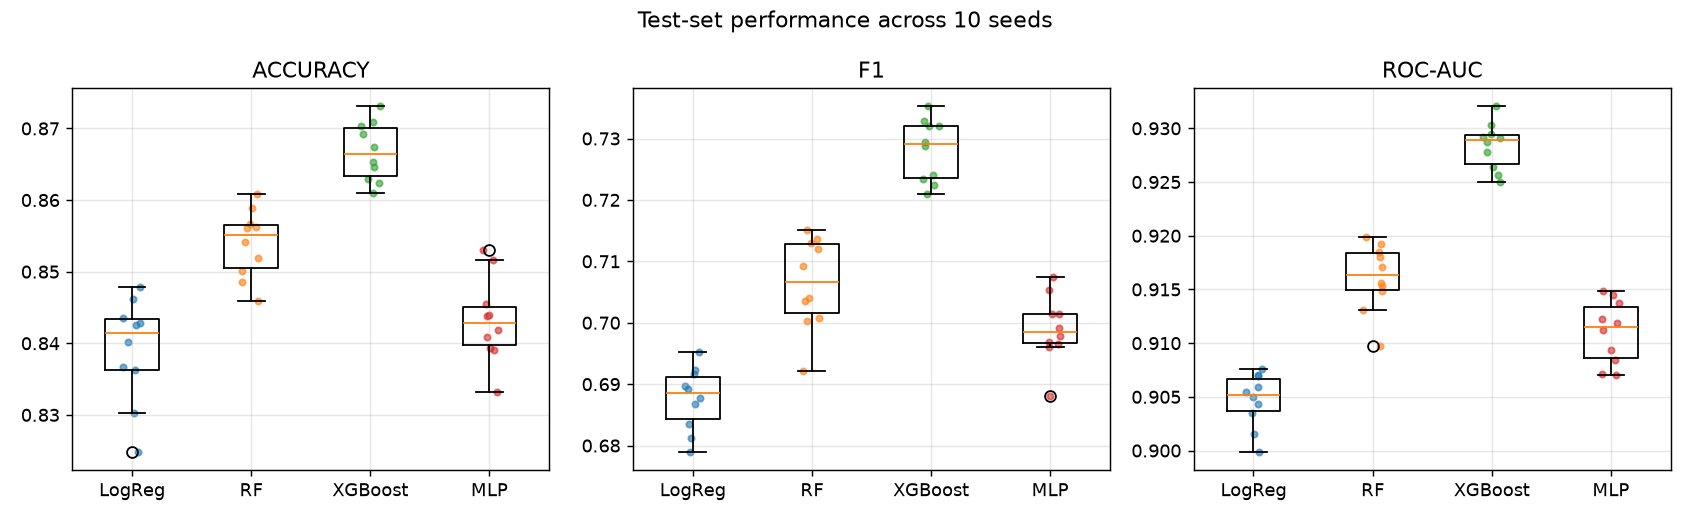

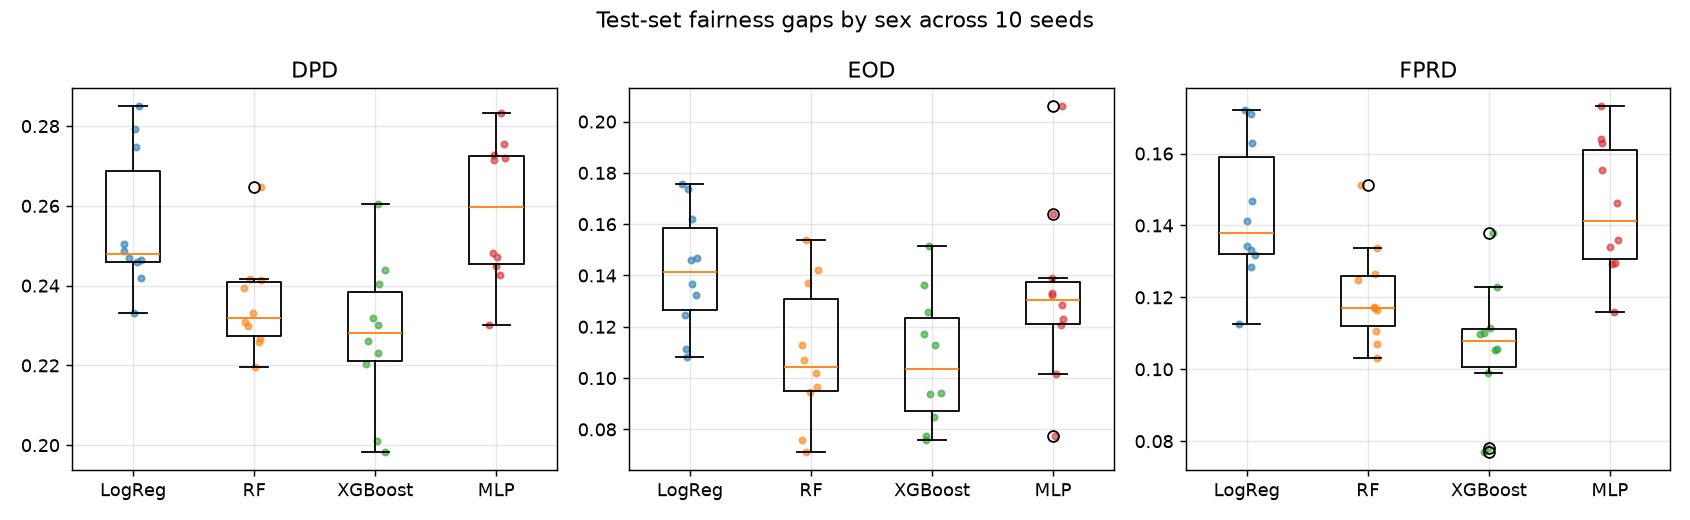

In [7]:
from IPython.display import Image, display
display(Image(os.path.join(mr.OUT,'box_performance.png'))); display(Image(os.path.join(mr.OUT,'box_fairness.png')))

## Reading the results
The cells above are computed. The interpretation is in the README section "Repeated runs (10 seeds)" and is based on these outputs: the spread of each metric across seeds, how often the ranking holds, and whether the mitigation rule picks the same point.